In [1]:
from langchain_groq import ChatGroq
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
llm=ChatGroq(model="openai/gpt-oss-120b")
translator_llm=ChatGroq(model="qwen/qwen3.8-27b")

In [3]:

class SubState(TypedDict):

    input_text: str
    translated_text: str

In [4]:
def translate_text(state: SubState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["input_text"]}
""".strip()
    
    translated_text = translator_llm.invoke(prompt).content

    return {'translated_text': translated_text}

In [5]:

subgraph_builder = StateGraph(SubState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

In [6]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str

In [7]:

def generate_answer(state: ParentState):

    answer = llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [8]:

def translate_answer(state: ParentState):

    # call the subgraph
    result = subgraph.invoke({'input_text': state['answer_eng']})

    return {'answer_hin': result['translated_text']}

In [9]:

parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", translate_answer)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

In [10]:
graph=parent_builder.compile()

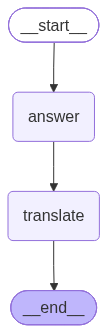

In [11]:
graph

In [12]:
graph.invoke({"question":"tell me about gradient descent "})

{'question': 'tell me about gradient descent ',
 'answer_eng': '**Gradient Descent – A Clear Overview**\n\n---\n\n### 1. What Is Gradient Descent?\nGradient descent (GD) is an iterative optimization algorithm used to find the minimum of a differentiable function. In machine‑learning and deep‑learning, it’s the workhorse for training models: it adjusts the model’s parameters so that a loss (error) function becomes as small as possible.\n\n---\n\n### 2. Core Idea (Intuition)\n\n1. **Loss surface** – Imagine a hilly landscape where the height at each point represents the loss value for a particular set of parameters.  \n2. **Gradient** – The gradient (∇L) at a point is a vector that points in the direction of steepest *increase* of the loss.  \n3. **Descent step** – To go downhill (reduce loss), we move **opposite** to the gradient.\n\n---\n\n### 3. Basic Algorithm\n\nFor a parameter vector\u202fθ and a loss function\u202fL(θ):\n\n1. **Initialize** θ₀ (randomly or with heuristics).  \n2. 